# The six BCBS shocks step by step: the 0.417 scalar, the +25.4 bp steepener and the -1.6 bp flattener

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (the 19 bands, the gap and the EVE)
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- build each of the six standard shock shapes (parallel up and down, short up and down, steepener, flattener) from its two scalars and its sizes, and print every intermediate;
- reproduce the standard's worked example (0.417, +41.7 bp, +25.4 bp and -1.6 bp at 3.5 years) with the engine and read the golden test that holds it;
- say where the sizes come from (the 2016 and the 2024 tables, and the table of the Chilean regulator), and what the engine does when a currency has no size;
- apply a post-shock floor and say which buckets it binds in, with the zero floor and with the maturity-dependent floor of the European Union;
- check each shape against the committed one, naming the engine version that baked it.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import shocks, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Data

Three committed documents feed the notebook:

- `data/derived/C14/vd-2022-q2.json` (case C14, the bank that failed in 2023 at 2022-06-30): the four scenario blocks with the six shock shapes in basis points at the 19 midpoints, the floors, the zero curve and the committed test rows. Sources: FDIC call reports and the US Treasury par curve, both `mirror-allowed`; real in aggregate, synthetic in behaviour.
- `data/derived/C14/models-svb-2021-2022.json`: the shock tables as fixtures (the 2016 calibration of BCBS d368 and the 2024 calibration in force from 2026-01-01) and the shape constants.
- `data/derived/C15/short-uf.json` (case C15, the synthetic Banco Andino on a CLP and UF balance sheet): the shock sizes of the Chilean regulator for the peso and the UF. Sources: the CMF (RAN 21-13 Annex 1) and the Banco Central de Chile curves, `mirror-allowed`; the bank is synthetic.

Shock sizes are in basis points. The next cell loads the three documents.

In [2]:
# Load the three documents (the notebook sits three folders below the repository root) and the 19 midpoints
ROOT = Path("../../..").resolve()
c14 = json.loads((ROOT / "data" / "derived" / "C14" / "vd-2022-q2.json").read_text(encoding="utf-8"))
models = json.loads((ROOT / "data" / "derived" / "C14" / "models-svb-2021-2022.json").read_text(encoding="utf-8"))
c15 = json.loads((ROOT / "data" / "derived" / "C15" / "short-uf.json").read_text(encoding="utf-8"))
out14, out15 = c14["outputs"], c15["outputs"]
MID = slotting.bucket_grid().midpoints
LANG = "en"  # the bilingual fields of the documents are read in this language
# Names of the document's own values in this language (the identifiers of the file stay as they are)
NAME = {"parallel-up": "parallel up", "parallel-down": "parallel down", "steepener": "steepener",
        "flattener": "flattener", "short-up": "short up", "short-down": "short down",
        True: "yes", False: "no"}

print("C14:", out14["valuation_date"], "| baked by riskvalidation", c14["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print("C15:", out15["as_of"], "| baked by riskvalidation", c15["provenance"]["riskvalidation_version"])
print("scenario blocks of C14:", [(s["calibration"], s["nmd_assumption"]) for s in out14["scenarios"]])
print("order of the six shocks in the engine:", shocks.SHOCKS)

C14: 2022-06-30 | baked by riskvalidation 0.9.0 | installed 0.9.0
C15: 2026-09-03 | baked by riskvalidation 0.9.0
scenario blocks of C14: [('2024', 'behavioural'), ('2024', 'contractual'), ('2016', 'behavioural'), ('2016', 'contractual')]
order of the six shocks in the engine: ('parallel-up', 'parallel-down', 'steepener', 'flattener', 'short-up', 'short-down')


## Method

The method has six steps: (1) the two scalars, (2) the six shapes, (3) the standard's worked example and the engine's golden test, (4) the sizes by currency and calibration, (5) the shapes on the 19 midpoints against the committed ones, (6) the post-shock floors.

### Step 1: the two scalars

Every shape is built from a decaying scalar for the short end and its complement for the long end. With $t_k$ the midpoint of band $k$ in years and $x = 4$ (SRP31.91, footnote 8: "$x = 4$ for most currencies unless otherwise determined by national supervisors"):

$$\alpha_{short}(t_k) = e^{-t_k / x}, \qquad \alpha_{long}(t_k) = 1 - e^{-t_k / x}$$

(source: BCBS, SRP31.91 and SRP31.92, https://www.bis.org/basel_framework/chapter/SRP/31.htm; dossier 01, H.2). The short scalar is close to one at the short end and decays; the long scalar is its complement, so the two always add up to one. The engine's `shock_scalars` returns both at any list of times. The next cell prints them at some of the 19 midpoints.

In [3]:
# The two scalars at some midpoints, and the check that they add up to one
alpha_short, alpha_long = shocks.shock_scalars(MID)
print(f"{'band':>6s} {'midpoint (y)':>14s} {'short scalar':>16s} {'long scalar':>16s}")
for k in (0, 3, 6, 9, 12, 15, 18):
    print(f"{k + 1:6d} {MID[k]:14.4f} {alpha_short[k]:16.4f} {alpha_long[k]:16.4f}")
print("the two scalars add up to one in every band:", NAME[bool(np.allclose(alpha_short + alpha_long, 1.0))])

  band   midpoint (y)     short scalar      long scalar
     1         0.0028           0.9993           0.0007
     4         0.3750           0.9105           0.0895
     7         1.2500           0.7316           0.2684
    10         3.5000           0.4169           0.5831
    13         6.5000           0.1969           0.8031
    16         9.5000           0.0930           0.9070
    19        25.0000           0.0019           0.9981
the two scalars add up to one in every band: yes


### Step 2: the six shapes

With the three sizes of a currency, the parallel size $\bar S_{par}$, the short size $\bar S_{short}$ and the long size $\bar S_{long}$ (in basis points), the six shapes are (BCBS, SRP31.90 to SRP31.92; dossier 01, H.2):

$$\Delta S_{par}(t_k) = \pm \bar S_{par}, \qquad \Delta S_{short}(t_k) = \pm \bar S_{short}\, \alpha_{short}(t_k), \qquad \Delta S_{long}(t_k) = \pm \bar S_{long}\, \alpha_{long}(t_k)$$

$$\Delta S_{steep}(t_k) = -0.65\, |\Delta S_{short}(t_k)| + 0.9\, |\Delta S_{long}(t_k)|$$

$$\Delta S_{flat}(t_k) = +0.8\, |\Delta S_{short}(t_k)| - 0.6\, |\Delta S_{long}(t_k)|$$

The long shock is used only inside the two rotations: the engine's six scenario shapes are parallel up and down, short up and down, steepener and flattener. The steepener lowers the short end and raises the long end, the flattener does the reverse. The next cell works the standard's own example by hand at the 3.5-year midpoint with both the short and the long size at 100 bp, printing every intermediate, and then asks the engine for the same shapes with `shock_curve`. It is a check of the definition on one point, not a second implementation of the function; the engine remains the method.

In [4]:
# The worked example of SRP31.92 by hand at 3.5 years with every intermediate, then the engine's shape for each of the six shocks
t = np.array([3.5])
a_short, a_long = shocks.shock_scalars(t)
size = 100.0
short_abs, long_abs = size * a_short[0], size * a_long[0]
print("short scalar at 3.5 years:", round(float(a_short[0]), 4), "| long scalar:", round(float(a_long[0]), 4))
print("|short shock| =", round(float(short_abs), 2), "pb | |long shock| =", round(float(long_abs), 2), "pb")
by_hand = {"short-up": short_abs, "steepener": -0.65 * short_abs + 0.9 * long_abs, "flattener": 0.8 * short_abs - 0.6 * long_abs}
for shock in shocks.SHOCKS:
    value = float(shocks.shock_curve(shock, size, size, size, t)[0])
    check = "" if shock not in by_hand else f" | by hand {by_hand[shock]:8.4f} | equal {NAME[bool(np.isclose(value, by_hand[shock]))]}"
    print(f"{NAME[shock]:22s} engine {value:9.4f} pb{check}")

short scalar at 3.5 years: 0.4169 | long scalar: 0.5831
|short shock| = 41.69 pb | |long shock| = 58.31 pb
parallel up            engine  100.0000 pb
parallel down          engine -100.0000 pb
steepener              engine   25.3864 pb | by hand  25.3864 | equal yes
flattener              engine   -1.6393 pb | by hand  -1.6393 | equal yes
short up               engine   41.6862 pb | by hand  41.6862 | equal yes
short down             engine  -41.6862 pb


### Step 3: the golden test of the standard's example

The standard prints its example with a rounded precision: 0.417, +41.7 bp, +25.4 bp and -1.6 bp. The engine holds those four values as a validation test, `irrbb.srp31_92_goldens`, that recomputes them and compares them with the printed ones within a tolerance of 0.0005 for the scalar and 0.05 bp for the shapes (a Contraste internal gate, not a regulatory one). The statistic is the largest absolute deviation. The next cell runs the test, prints each value beside its printed counterpart, and compares it with the row the document committed.

In [5]:
# Run the golden test, print each value beside the printed one, and compare with the committed row (and the version that baked it)
golden = rv_irrbb.srp31_92_goldens()
print("test_id:", golden.test_id, "| light", golden.light.value, "| n =", golden.n)
print(f"{'':12s} {'engine':>10s} {'printed':>10s} {'deviation':>12s}")
for name, value in golden.extras["values"].items():
    print(f"{name:12s} {value:10.4f} {golden.extras['printed'][name]:10.4f} {golden.extras['deviations'][name]:12.4f}")
print("statistic (largest deviation):", round(golden.statistic, 4), "| tolerances:", golden.extras["thresholds"])
committed = next(row for row in c14["tests"] if row["test_id"] == "irrbb.srp31_92_goldens")
print("committed row baked by riskvalidation", c14["provenance"]["riskvalidation_version"], "| same values:", NAME[bool(np.allclose(list(committed["extras"]["values"].values()), list(golden.extras["values"].values())))])

test_id: irrbb.srp31_92_goldens | light green | n = 4
                 engine    printed    deviation
alpha_short      0.4169     0.4170       0.0001
short-up        41.6862    41.7000       0.0138
steepener       25.3864    25.4000       0.0136
flattener       -1.6393    -1.6000       0.0393
statistic (largest deviation): 0.0393 | tolerances: {'tolerance_scalar': 0.0005, 'tolerance_bp': 0.05}
committed row baked by riskvalidation 0.9.0 | same values: yes


### Step 4: the sizes by currency and calibration

The sizes are a table, not a formula. The Basel Committee calibrated them on historical changes of rates and published two tables: the 2016 one (BCBS d368, Annex 2, Table 1: data 2000 to 2015, 99th percentile of global factors, rounded to 50 bp) and the 2024 one that replaces it from 2026-01-01 (SRP31.90, Table 2, d578: data January 2000 to December 2023, 99.9th percentile of local six-month average absolute changes, rounded to 25 bp). The Chilean regulator publishes its own table in Annex 1 of RAN 21-13, which is the one the Chilean case uses. The engine holds the three as data: `shock_table` returns the sizes of a calibration as `{currency: (parallel, short, long)}`. The next cell prints three currencies in the two Basel calibrations, and the five rows of the Chilean table (a dash in the source is a missing value).

In [6]:
# Sizes in basis points of three currencies under the two Basel calibrations, and the rows of the Chilean table
t2016, t2024, tcmf = shocks.shock_table("2016"), shocks.shock_table("2024"), shocks.shock_table("cmf-annex1")
print(f"{'':6s} {'2016 (par, short, long)':>34s} {'2024 (par, short, long)':>34s}")
for currency in ("USD", "EUR", "JPY"):
    print(f"{currency:6s} {str(t2016[currency]):>34s} {str(t2024[currency]):>34s}")
print("currencies in each Basel table:", len(t2016), len(t2024), "| CLP in the Basel tables:", NAME["CLP" in t2024 or "CLP" in t2016])
print("rows of the Chilean table (Annex 1, sheet 9):")
for row, sizes in tcmf.items():
    print(f"  {row:10s} {sizes}")

                  2016 (par, short, long)            2024 (par, short, long)
USD                 (200.0, 300.0, 150.0)              (200.0, 300.0, 225.0)
EUR                 (200.0, 250.0, 100.0)              (225.0, 350.0, 200.0)
JPY                 (100.0, 100.0, 100.0)              (100.0, 100.0, 100.0)
currencies in each Basel table: 21 21 | CLP in the Basel tables: no
rows of the Chilean table (Annex 1, sheet 9):
  canasta-1  (200.0, 300.0, 150.0)
  canasta-2  (400.0, 500.0, 300.0)
  CLP        (300.0, 400.0, 200.0)
  UR-nii     (300.0, None, None)
  UR-eve     (200.0, 250.0, 150.0)


What the engine does with a currency that has no entry is a design decision worth reading. `shock_size` returns the size of a currency with its **origin** (which table it came from). For a currency without an entry it **refuses**: a size is never invented. The caller may supply an estimate, but then the size carries the origin `contraste-estimate`, a bilingual label and the method, so no estimate can pass for a regulatory parameter; and a currency that has a tabled size refuses an estimate. The next cell shows the three cases: the peso in the Basel table (refused), the peso and the UF in the Chilean table (tabled; the UF takes the `UR-eve` row), and an illustration of the labelled estimate for the peso, which only shows the mechanism and is not used by the product.

In [7]:
# The size of a currency with its origin: refused when there is no entry, tabled in the Chilean table, and the labelled estimate
try:
    shocks.shock_size("CLP", "2024")
except ValueError as error:
    print("refused:", str(error)[:110], "...")
for currency in ("CLP", "CLF"):
    z = shocks.shock_size(currency, "cmf-annex1")
    print(f"{currency}: parallel, short, long = {z.parallel_bp:.0f}, {z.short_bp:.0f}, {z.long_bp:.0f} pb | origin = {z.origin}")
label = {"en": "illustration only", "es": "solo ilustración"}
z = shocks.shock_size("CLP", "2024", estimate=(300.0, 400.0, 200.0, label, "illustration of the labelled-estimate path"))
print("estimate: origin =", z.origin, "|", z.label[LANG])

refused: CLP has no shock size under 2024: supply the size with its label and method (a size is never invented; CLP: us ...
CLP: parallel, short, long = 300, 400, 200 pb | origin = cmf-annex1
CLF: parallel, short, long = 200, 250, 150 pb | origin = cmf-annex1
estimate: origin = contraste-estimate | illustration only


The committed documents carry the size each scenario used, with its origin. The next cell compares the sizes the engine returns for the USD under the 2024 and the 2016 calibrations with the committed scenario blocks of C14, and the Chilean sizes with the committed ones of C15, for the EVE (six shocks) and for the NII (the single 300 bp parallel shock).

In [8]:
# Compare the engine's sizes with the sizes the committed scenarios used, in C14 (USD) and C15 (CLP and UF)
for calibration in ("2024", "2016"):
    z = shocks.shock_size("USD", calibration)
    used = next(s["shock_size"] for s in out14["scenarios"] if s["calibration"] == calibration)
    same = (z.parallel_bp, z.short_bp, z.long_bp, z.origin) == (used["parallel_bp"], used["short_bp"], used["long_bp"], used["origin"])
    print(f"USD {calibration}: {z.parallel_bp:.0f}/{z.short_bp:.0f}/{z.long_bp:.0f} pb, origin {z.origin} | equal to the committed size: {NAME[same]}")
for used in out15["eve_shock_sizes"]:
    z = shocks.shock_size(used["currency"], "cmf-annex1")
    same = (z.parallel_bp, z.short_bp, z.long_bp) == (used["parallel_bp"], used["short_bp"], used["long_bp"])
    print(f"EVE {used['currency']}: {used['parallel_bp']:.0f}/{used['short_bp']:.0f}/{used['long_bp']:.0f} pb, origin {used['origin']} | equal to the engine: {NAME[same]}")
print("NII:", [(x["currency"], x["parallel_bp"]) for x in out15["nii_shock_sizes"]], "| UR-nii of the Chilean table:", tcmf["UR-nii"])

USD 2024: 200/300/225 pb, origin srp31-table-2024 | equal to the committed size: yes
USD 2016: 200/300/150 pb, origin srp31-table-2016 | equal to the committed size: yes
EVE CLP: 300/400/200 pb, origin cmf-annex1 | equal to the engine: yes
EVE CLF: 200/250/150 pb, origin cmf-annex1 | equal to the engine: yes
NII: [('CLP', 300), ('CLF', 300)] | UR-nii of the Chilean table: (300.0, None, None)


### Step 5: the six shapes on the 19 midpoints

Now the six shapes for the USD under the 2024 calibration (200, 300 and 225 bp) at the 19 midpoints with `shock_curve`, compared with the shapes committed in the first scenario block of C14. The same cell then builds the steepener of the 2016 calibration (long size 150 bp instead of 225) and compares it with the committed 2016 block, to show how much the recalibration moves a rotation.

In [9]:
# The six shapes of the USD under the 2024 calibration at the 19 midpoints, against the committed shapes, and the 2016 steepener
size24 = shocks.shock_size("USD", "2024")
shapes = {s: shocks.shock_curve(s, size24.parallel_bp, size24.short_bp, size24.long_bp, MID) for s in shocks.SHOCKS}
block24 = out14["scenarios"][0]
committed_shapes = {row["shock"]: np.array(row["shape_bp"]) for row in block24["shocks"]}
print(f"{'':16s} {'band 1':>10s} {'band 10':>11s} {'band 19':>11s}   equal to the committed shape")
for s in shocks.SHOCKS:
    v = shapes[s]
    print(f"{NAME[s]:22s} {v[0]:10.2f} {v[9]:11.2f} {v[18]:11.2f}   {NAME[bool(np.allclose(v, committed_shapes[s]))]}")
size16 = shocks.shock_size("USD", "2016")
steep16 = shocks.shock_curve("steepener", size16.parallel_bp, size16.short_bp, size16.long_bp, MID)
block16 = next(s for s in out14["scenarios"] if s["calibration"] == "2016" and s["nmd_assumption"] == "behavioural")
committed16 = next(np.array(r["shape_bp"]) for r in block16["shocks"] if r["shock"] == "steepener")
print("steepener 2016 at band 19:", round(float(steep16[18]), 2), "pb | 2024:", round(float(shapes["steepener"][18]), 2), "pb | equal to the committed 2016:", NAME[bool(np.allclose(steep16, committed16))])

                     band 1     band 10     band 19   equal to the committed shape
parallel up                200.00      200.00      200.00   yes
parallel down             -200.00     -200.00     -200.00   yes
steepener                 -194.72       36.80      201.73   yes
flattener                  239.74       21.32     -134.28   yes
short up                   299.79      125.06        0.58   yes
short down                -299.79     -125.06       -0.58   yes
steepener 2016 at band 19: 134.36 pb | 2024: 201.73 pb | equal to the committed 2016: yes


### Step 6: the post-shock floors

A large downward shock on a low rate would push it far below zero. The standard lets supervisors floor the post-shock rates at a level not above zero (SRP31.93), and the engine's `apply_floor` applies

$$r_{shocked} = \max\left(r_0 + \frac{s}{10^4},\ \min(f,\ r_0)\right)$$

where $s$ is the shock in basis points, $r_0$ the base rate and $f$ the floor: a floor never lifts a rate above its own pre-shock value, so a rate already below the floor keeps its value. The floor can be a number or one value per band. Besides the zero floor, the engine holds the maturity-dependent floor of the European Union, `eu_floor`: $-1.5\%$ at immediate maturity, rising 0.03 percentage points a year to zero at 50 years (Commission Delegated Regulation (EU) 2024/856, Article 3(7), as cited by the engine; dossier 01, H.5). The next cell applies the zero floor to the USD zero curve of 2022-06-30 under the parallel-down shock of 200 bp, then lists the bands where the floor binds under each of the six shocks and compares with the buckets committed in the document.

In [10]:
# Apply the zero floor to the parallel-down shock on the zero curve, then list the bands where the floor binds for each shock
r0 = np.array(out14["curve"]["zero_rates_at_midpoints"])
floor = block24["floor"]
raw = shocks.apply_floor(r0, shapes["parallel-down"], None)
floored = shocks.apply_floor(r0, shapes["parallel-down"], floor)
print(f"{'band':>6s} {'base rate':>12s} {'shocked, no floor':>20s} {'shocked, floor 0':>20s}")
for k in range(5):
    print(f"{k + 1:6d} {r0[k]:12.5f} {raw[k]:20.5f} {floored[k]:20.5f}")
committed_bound = {row["shock"]: row["floor_bound_buckets"] for row in block24["shocks"]}
for s in shocks.SHOCKS:
    bound = [int(k) + 1 for k in np.flatnonzero(~np.isclose(shocks.apply_floor(r0, shapes[s], floor), shocks.apply_floor(r0, shapes[s], None)))]
    print(f"{NAME[s]:22s} bands where the floor binds: {bound} | equal to the committed: {NAME[bound == committed_bound[s]]}")

  band    base rate    shocked, no floor     shocked, floor 0
     1      0.01279             -0.00721              0.00000
     2      0.01279             -0.00721              0.00000
     3      0.01678             -0.00322              0.00000
     4      0.02105              0.00105              0.00105
     5      0.02566              0.00566              0.00566
parallel up            bands where the floor binds: [] | equal to the committed: yes
parallel down          bands where the floor binds: [1, 2, 3] | equal to the committed: yes
steepener              bands where the floor binds: [1, 2, 3] | equal to the committed: yes
flattener              bands where the floor binds: [] | equal to the committed: yes
short up               bands where the floor binds: [] | equal to the committed: yes
short down             bands where the floor binds: [1, 2, 3, 4] | equal to the committed: yes


The same comparison with the maturity-dependent floor of the European Union. The next cell prints its value at some maturities and lists the bands where it would bind for each of the six shocks on the same curve. This is a what-if on the committed curve: the committed scenarios use the zero floor.

In [11]:
# The maturity-dependent floor of the European Union at some maturities, and the bands where it would bind for the same shocks
print("EU floor at 0, 1, 5, 10, 25, 50 and 60 years:", [round(float(x), 4) for x in shocks.eu_floor(np.array([0.0, 1.0, 5.0, 10.0, 25.0, 50.0, 60.0]))])
eu = shocks.eu_floor(MID)
for s in shocks.SHOCKS:
    bound = np.flatnonzero(~np.isclose(shocks.apply_floor(r0, shapes[s], eu), shocks.apply_floor(r0, shapes[s], None)))
    print(f"{NAME[s]:22s} bands where the EU floor binds: {[int(k) + 1 for k in bound]}")

EU floor at 0, 1, 5, 10, 25, 50 and 60 years: [-0.015, -0.0147, -0.0135, -0.012, -0.0075, 0.0, 0.0]
parallel up            bands where the EU floor binds: []
parallel down          bands where the EU floor binds: []
steepener              bands where the EU floor binds: []
flattener              bands where the EU floor binds: []
short up               bands where the EU floor binds: []
short down             bands where the EU floor binds: [1, 2]


The last cell draws the six shapes for the USD under the 2024 calibration against the midpoint of the band, and, on the right, the parallel-down shock before and after the zero floor on the zero curve. On the left the short shocks fade with the horizon, the parallel ones stay flat, and the steepener and the flattener cross zero at different horizons. On the right the floor takes the first bands of the shocked curve back to zero.

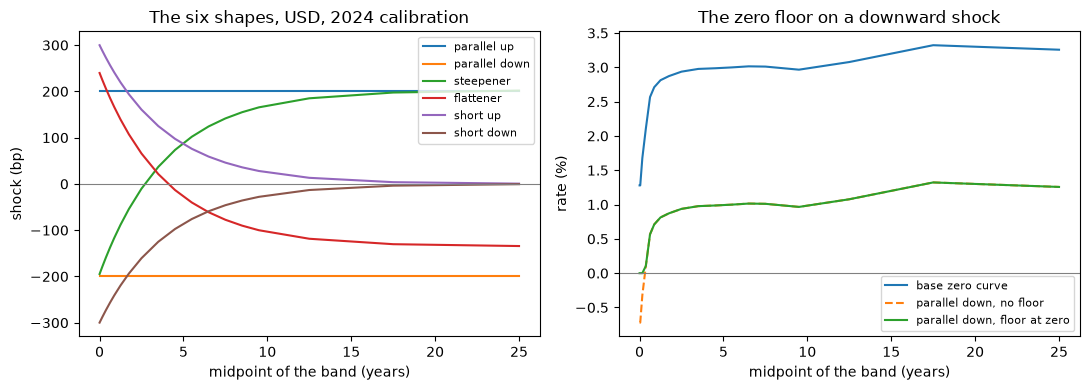

In [12]:
# Draw the six shapes and the effect of the zero floor on the parallel-down shock
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
for s in shocks.SHOCKS:
    left.plot(MID, shapes[s], label=NAME[s])
left.axhline(0, color="grey", linewidth=0.8)
left.set_xlabel("midpoint of the band (years)")
left.set_ylabel("shock (bp)")
left.set_title("The six shapes, USD, 2024 calibration")
left.legend(fontsize=8)
right.plot(MID, r0 * 100, label="base zero curve")
right.plot(MID, raw * 100, linestyle="--", label="parallel down, no floor")
right.plot(MID, floored * 100, label="parallel down, floor at zero")
right.axhline(0, color="grey", linewidth=0.8)
right.set_xlabel("midpoint of the band (years)")
right.set_ylabel("rate (%)")
right.set_title("The zero floor on a downward shock")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Results

- **The scalars and the example.** At 3.5 years the short scalar is 0.4169 (the standard prints 0.417) and the long scalar 0.5831. With 100 bp sizes the short shock is 41.69 bp, the steepener +25.39 bp and the flattener -1.64 bp, each equal to the hand calculation of the definition. The golden test `irrbb.srp31_92_goldens` is green with deviations of 0.0001, 0.0138, 0.0136 and 0.0393 against the tolerances of 0.0005 and 0.05; the flattener is the furthest from the printed value because the standard rounds to one decimal (-1.6393 against -1.6). The gate is therefore "equal at the printed precision", not "equal to the last digit", and the committed row holds the same four values.
- **The sizes.** For the USD only the long size moves between the calibrations (150 bp in 2016, 225 bp in 2024); for the EUR all three do (200/250/100 to 225/350/200); the JPY does not move. Both Basel tables have 21 currencies and neither has the peso, so the engine refuses a size for it instead of inventing one; the Chilean table gives the peso 300/400/200 bp and the UF 200/250/150 bp for the EVE, and a single 300 bp parallel shock for both for the NII. A validator should read the origin of every size before reading any result: it says whose number it is.
- **The shapes.** The six shapes of the USD in 2024 equal the committed ones. The steepener is the shape the recalibration moves most: its long end is +134.36 bp with the 2016 sizes and +201.73 bp with the 2024 ones, because the long size went from 150 to 225 bp. The flattener, in contrast, is large at the short end (+239.74 bp in band 1) and negative at the long end (-134.28 bp in band 19).
- **The floors.** With the base curve of 2022-06-30 (1.28 percent in the first bands) the zero floor binds in bands 1 to 3 under the parallel-down shock and the steepener, and in bands 1 to 4 under the short-down shock; it never binds under the upward shocks or the flattener, and the lists equal the committed ones. In band 1 the parallel-down shock would give -0.721 percent, which the floor takes back to zero. The maturity-dependent floor of the European Union starts at -1.5 percent and binds only under the short-down shock, in bands 1 and 2. The floor changes the shocked curve, so it changes every delta EVE that reads that curve: the committed numbers of the next notebooks already include it.
- **What the notebook does not show.** How a shape reaches the cash flows to give a change in EVE (notebooks 03 and 06), the sizes of the NII shocks beyond the single parallel one, and the calibration of the sizes themselves, which the standard describes in SRP98 and the engine takes as data.

## Summary

- The six shapes come from two scalars, $e^{-t/4}$ and its complement, and three sizes per currency: the parallel and short shocks use one scalar each, and the steepener and the flattener rotate with the weights -0.65 and +0.9, and +0.8 and -0.6.
- The standard's own example, 0.417, +41.7 bp, +25.4 bp and -1.6 bp at 3.5 years, is a golden test of the engine, green within its tolerance, and the flattener is the value furthest from the printed one.
- The sizes are a table: two Basel calibrations, 2016 and 2024, and the Chilean table. A currency without an entry is refused, and an estimate carries its label and method.
- A floor never lifts a rate above its pre-shock value; the zero floor binds in the short bands of the USD curve of mid-2022 under the downward shocks, and the maturity-dependent EU floor binds only under the short-down shock, in two bands.
- Every shape and every list of bands recomputed here equals the committed one, baked by the same engine version.

**What to try next.** Change the long size of `shock_curve` and watch which of the two rotations moves more. Then continue with notebook 03, the behavioural layer.

## References

- BCBS, Standards: Interest rate risk in the banking book, SRP31.90 to SRP31.93 (the six shocks, the sizes and the floor) and SRP31.96 (the 19 time buckets). https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book, Annex 2, Table 1 (the 2016 calibration). https://www.bis.org/bcbs/publ/d368.htm
- BCBS (2024), d578, Recalibration of shocks for interest rate risk in the banking book (the 2024 calibration, in force from 2026-01-01). https://www.bis.org/publications/202407-standards-recalibration-shocks-interest-rate-risk-banking-book.pdf
- CMF, Recopilacion Actualizada de Normas, chapter 21-13, Annex 1, sheet 9 (the Chilean shock sizes), as transcribed in the engine and in dossier 03, F.2.
- Commission Delegated Regulation (EU) 2024/856, Article 3(7) (the maturity-dependent floor), as cited by the engine. https://eur-lex.europa.eu/eli/reg_del/2024/856/oj/eng
- Dossier 01 of the Contraste research (Basel framework), section H.2 to H.3.